In [1]:
# @title
%env GEMINI_API_KEY=  AQ.Ab8RN6Ik4zGv3GV_muI2tN2r5aNJGa26BtdFCA-EFYFFmSeU8A

env: GEMINI_API_KEY=AQ.Ab8RN6Ik4zGv3GV_muI2tN2r5aNJGa26BtdFCA-EFYFFmSeU8A


In [2]:
!pip install -q transformers pillow google-genai

In [3]:
from google import genai
import os
# Client will be initialized in the next cell after API key check


In [4]:
if "GEMINI_API_KEY" not in os.environ:
  print("please set your Gemini API key in the environment variable GEMINI_API_KEY")
else:
  client=genai.Client(api_key=os.environ["GEMINI_API_KEY"])
  MODEL="gemini-3.8-flash"
  print("Gemini client initialized successfully.")

Gemini client initialized successfully.


In [5]:
import time

prompt=input("Enter your Story prompt and press enter:\n")
if prompt.strip()=="":
  print("No prompt entered , Exiting.")
else:
  print(f"Generating story for prompt: {prompt}")
  print("It may take few seconds")

  # List of models to try in case one hits quota/rate limits
  candidate_models = [
      MODEL,
      "gemini-2.0-flash",
      "gemini-1.5-flash",
      "gemini-1.5-pro"
  ]

  story_generated = False
  for m in candidate_models:
    try:
      resp = client.models.generate_content(model=m, contents=[prompt])
      print(f"\n----Generated Story (using {m})----\n")
      print(resp.text)
      story_generated = True
      break
    except Exception as e:
      err_str = str(e)
      if "429" in err_str or "RESOURCE_EXHAUSTED" in err_str:
        print(f"⚠️ Free tier quota exhausted for {m}. Trying fallback model...")
        time.sleep(1)
        continue
      elif "503" in err_str or "UNAVAILABLE" in err_str:
        print(f"⚠️ Server busy for {m}. Trying fallback model...")
        time.sleep(1)
        continue
      else:
        print(f"Error with {m}: {e}")
        break

  if not story_generated:
    print("\n❌ All candidate models reached their daily free limit. You can either:")
    print("1. Create a new free API key at https://aistudio.google.com and update Cell 0.")
    print("2. Wait for the daily quota reset.")


Generating story for prompt: final year engineering getting placed in a company
It may take few seconds

----Generated Story (using gemini-3.8-flash)----

Congratulations! Getting placed in your final year is a massive milestone—it takes off an immense amount of pressure and gives you a clear runway toward your career.

Here is a practical roadmap of what you should do between now and your first day on the job:

---

### 1. Lock Down the Formalities (Now)
* **Read the fine print:** Carefully review your Offer Letter / Letter of Intent (LOI). Look for:
  * **CTC Breakdown:** Fixed pay vs. variable pay, bonuses, and deductions (PF, taxes, insurance).
  * **Service Agreements / Bonds:** Understand if there is a minimum tenure or financial penalty for leaving early.
  * **Probation Period:** Check the duration and conditions for full-time confirmation.
* **Keep your documents organized:** Digitize your mark sheets, ID proofs (PAN, Aadhaar/Passport), resume, and certificates. Companies run 

In [7]:
!pip install -q transformers pillow google-genai timm

In [8]:
from transformers import BlipProcessor,BlipForConditionalGeneration
from PIL import Image
from google import genai
import os
import io

In [9]:
if "GEMINI_API_KEY" not in os.environ:
  print("please set your Gemini API key in the environment variable GEMINI_API_KEY")
else:
  client=genai.Client(api_key=os.environ["GEMINI_API_KEY"])
  MODEL="gemini-3.8-flash"
  print("Gemini client initialized successfully.")

Gemini client initialized successfully.


In [10]:
processor=BlipProcessor.from_pretrained("Salesforce/blip-image-captioning-large")
model=BlipForConditionalGeneration.from_pretrained("Salesforce/blip-image-captioning-large")



Loading weights:   0%|          | 0/616 [00:00<?, ?it/s]

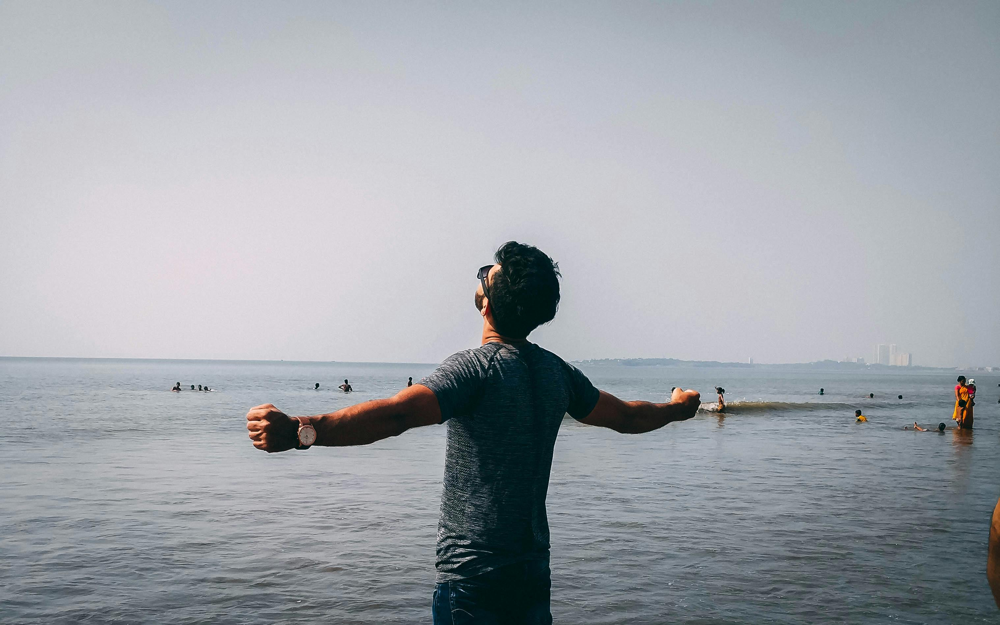

Loaded: C:\Users\MEGHA SRIWASTVA\OneDrive\Pictures\output.png


In [11]:
from PIL import Image

try:
  from google.colab import files
  uploaded=files.upload()
  for fn in uploaded.keys():
    image=Image.open(fn).convert('RGB')
    display(image)
except ModuleNotFoundError:
  # Running locally — enter the image file path directly
  file_path = input("Enter the full path to your image file:\n").strip().strip('"')
  if file_path:
    image = Image.open(file_path).convert('RGB')
    display(image)
    print(f"Loaded: {file_path}")
  else:
    print("No path entered. Please run this cell again.")


In [12]:
inputs=processor(images=image,return_tensors='pt')
out=model.generate(**inputs)

caption=processor.decode(out[0],skip_special_tokens=True)
print("Caption generated by BLIP: ")
print(caption)


C:\Users\MEGHA SRIWASTVA\AppData\Roaming\Python\Python314\site-packages\transformers\generation\utils.py:1963: UserWarning: Using the model-agnostic default `max_length` (=21) to control the generation length. We recommend setting `max_new_tokens` to control the maximum length of the generation.
  warnings.warn(


Caption generated by BLIP: 
there is a man standing in the water with his arms outstretched


In [13]:
import time

story_prompt=(f"write a short story in hinglish(around 500-700 words) based on this scene description: {caption}")
print(story_prompt)
print("Sending this to Gemini.\n")

# Candidate models to try in case of quota exhaustion
candidate_models = [
    MODEL,
    "gemini-2.0-flash",
    "gemini-1.5-flash",
    "gemini-1.5-pro"
]

story = ""
for m in candidate_models:
  try:
    response = client.models.generate_content(model=m, contents=[story_prompt])
    story = response.text
    print(f"\n----Generated Story (using {m})----\n")
    print(story)
    break
  except Exception as e:
    err_str = str(e)
    if "429" in err_str or "RESOURCE_EXHAUSTED" in err_str:
      print(f"⚠️ Free tier quota exhausted for {m}. Trying fallback model...")
      time.sleep(1)
      continue
    elif "503" in err_str or "UNAVAILABLE" in err_str:
      print(f"⚠️ Server busy for {m}. Trying fallback model...")
      time.sleep(1)
      continue
    else:
      print(f"Error with {m}: {e}")
      break

if not story:
  print("\n❌ Could not generate story due to API limits. You may need a fresh API key.")


write a short story in hinglish(around 500-700 words) based on this scene description: there is a man standing in the water with his arms outstretched
Sending this to Gemini.


----Generated Story (using gemini-3.8-flash)----

Sham dhal chuki thi. Aasmaan par narangi aur deep purple rang ka ek ajeeb sa mel tha, jaise din aur raat ek doosre se aakhri baar gale mil rahe hon. Arabian Sea ki leherein shor machaate hue kinare se takra rahi theen. Shore par door-door tak koi nahi tha, sirf Kabir aur uske andar chalta hua ek behisaab toofan.

Pichhle do saal Kabir ke liye kisi dhuen ke baadal jaise rahe the. Corporate job ka suffocating pressure, ek toota hua rishta jisme usne apna sab kuch daanv par laga diya tha, aur wo unkahe lafz jo wo kabhi keh nahi paaya. Shehar ki bheed mein rehte hue bhi wo itna akela mehsoos karta tha ki kabhi-kabhi saans lena bhi ek task lagta tha. Har waqt har cheez ko control karne ki koshish—circumstances ko, emotions ko, logon ke opinions ko—ne uske wajood ko ni

In [14]:
if 'story' in locals() and story:
  with open("generated_story.txt", "w", encoding="utf-8") as f:
    f.write(story)
  print("Story saved to generated_story.txt")
  import os
  full_path = os.path.abspath("generated_story.txt")
  print(f"File saved at: {full_path}")

  try:
    from google.colab import files
    files.download("generated_story.txt")
  except ModuleNotFoundError:
    pass
else:
  print("⚠️ No story content found to save. Please make sure Cell 11 runs successfully first.")


Story saved to generated_story.txt
File saved at: c:\Users\MEGHA SRIWASTVA\OneDrive\Documents\Desktop\AI-StoryTeller\generated_story.txt


In [15]:
!pip install -q ipywidgets

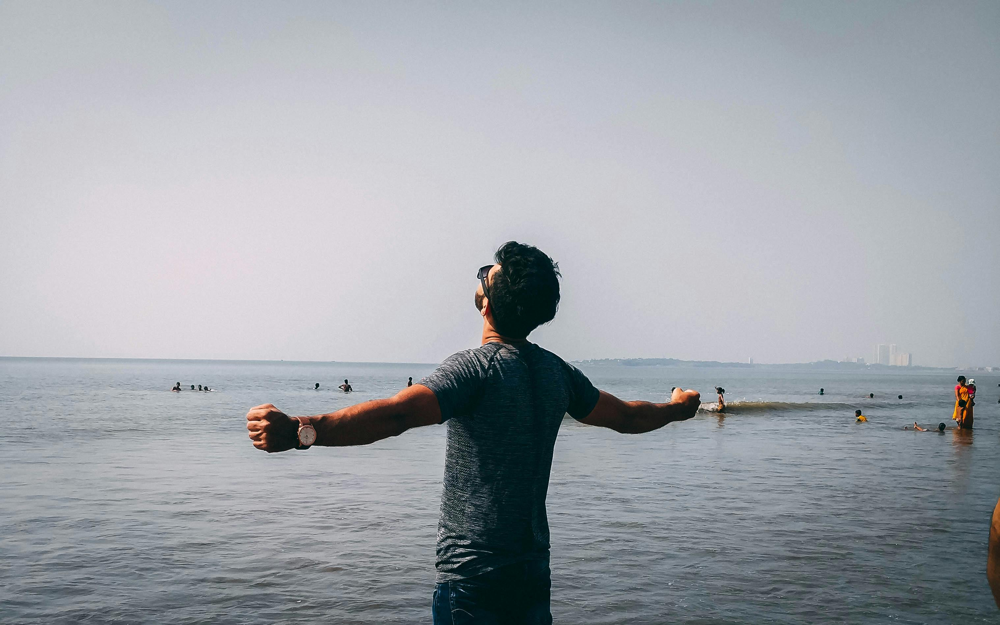

Loaded: C:\Users\MEGHA SRIWASTVA\OneDrive\Pictures\output.png


In [16]:
from PIL import Image
import os

images=[]
image_names=[]

try:
  from google.colab import files
  import io
  uploaded=files.upload()
  for name,file in uploaded.items():
    image=Image.open(io.BytesIO(file)).convert('RGB')
    image_names.append(name)
    images.append(image)
    display(image)
except ModuleNotFoundError:
  # Running locally — enter image paths separated by commas
  paths_input = input("Enter image file paths (separated by commas):\n").strip()
  for fp in paths_input.split(","):
    fp = fp.strip().strip('"')
    if fp and os.path.exists(fp):
      img = Image.open(fp).convert('RGB')
      images.append(img)
      image_names.append(os.path.basename(fp))
      display(img)
      print(f"Loaded: {fp}")
    elif fp:
      print(f"File not found: {fp}")
  if not images:
    print("No images loaded. Please run this cell again.")

In [17]:
from transformers import BlipProcessor,BlipForConditionalGeneration

processor=BlipProcessor.from_pretrained("Salesforce/blip-image-captioning-large")
blip_model=BlipForConditionalGeneration.from_pretrained("Salesforce/blip-image-captioning-large")

captions=[]

for img in images:
  inputs=processor(images=img,return_tensors='pt')
  out=blip_model.generate(**inputs,max_new_tokens=30)
  caption=processor.decode(out[0],skip_special_tokens=True)
  captions.append(caption)

print("captions generated from images: ")
for i,caption in enumerate(captions):
  print(f"{image_names[i]}: {caption}")

Loading weights:   0%|          | 0/616 [00:00<?, ?it/s]

captions generated from images: 
output.png: there is a man standing in the water with his arms outstretched


In [18]:
import ipywidgets as widgets
from IPython.display import display, clear_output


tone_dropdown = widgets.Dropdown(
    options=["whimsical", "adventurous", "suspenseful", "romantic", "sci-fi", "mystery"],
    value="adventurous",
    description="Tone:"
)

length_dropdown = widgets.Dropdown(
    options=["Short (100–200 words)", "Medium (200–400 words)", "Long (400–600 words)"],
    value="Medium (200–400 words)",
    description="Length:"
)

generate_button = widgets.Button(description="Generate Story")
output_box = widgets.Output()

display(tone_dropdown, length_dropdown, generate_button, output_box)


Dropdown(description='Tone:', index=1, options=('whimsical', 'adventurous', 'suspenseful', 'romantic', 'sci-fi…

Dropdown(description='Length:', index=1, options=('Short (100–200 words)', 'Medium (200–400 words)', 'Long (40…

Button(description='Generate Story', style=ButtonStyle())

Output()

In [19]:
def on_generate_clicked(b):
    with output_box:
        clear_output()

        tone = tone_dropdown.value
        length_map = {
            "Short (100–200 words)": "100–200 words",
            "Medium (200–400 words)": "200–400 words",
            "Long (400–600 words)": "400–600 words"
        }
        length = length_map[length_dropdown.value]

        caption_prompt = "\n".join([f"- {c}" for c in captions])

        outline_prompt = (
            f"Using the following scene descriptions, create a 4-chapter story outline. "
            f"Each chapter should have a title and a short summary.\n\n"
            f"{caption_prompt}\n\nOutline:"
        )

        try:
            outline_response = client.models.generate_content(model=MODEL, contents=outline_prompt)
            outline_text = outline_response.text
            print(" Story Outline:\n")
            print(outline_text)


            full_story = ""
            for i in range(1, 5):  # generates all 4 chapters
                chapter_prompt = (
                    f"Using the outline below, write Chapter {i} in a {tone} tone. "
                    f"Make it {length}. Add vivid details, good pacing, and consistent characters.\n\n"
                    f"{outline_text}\n\nChapter {i}:"
                )

                chapter_response = client.models.generate_content(model=MODEL, contents=chapter_prompt)
                chapter_text = chapter_response.text
                print(f"\n Chapter {i}:\n")
                print(chapter_text)
                full_story += f"\n\nChapter {i}:\n{chapter_text}"


            with open("multi_image_story.txt", "w") as f:
                f.write(full_story)
            print("\n Story saved as multi_image_story.txt")

            try:
                from google.colab import files
                files.download("multi_image_story.txt")
            except ModuleNotFoundError:
                pass

        except Exception as e:
            print(" Error generating story:", e)

generate_button.on_click(on_generate_clicked)

In [20]:
!pip install -q gtts reportlab

In [21]:
#you can paste your story here or load grom file
story_text = """

Wah, ek alien ki kahani, Hindustani tadke ke saath! Chalo sunte hain...

---

**Title: Chai Aur Ek Tara**

**Part 1: Pahadi Subah Aur Ek Anjaani Roshni**

Himachal ke khoobsurat pahadon mein, Jahan Har subah suraj ki kirnein devdaar ke pedon ko sone sa chamkaati theen, wahaan Raju apni chhoti si chai ki dukaan chalaata tha. Raju, koi khaas aadmi nahi tha, seedha saadha, dil ka achha, aur uski chai? Uski chai toh poore ilaake mein famous thi. Garma garam adrak wali chai aur saath mein biscoot, bas!

Ek din, subah ke 4 baje the, jab Raju apni dukaan kholne jaa raha tha. Aasmaan abhi bhi taaron se bhara tha. Tabhi usne dekha, ek ajeeb si roshni, bahut tez, jo tezi se neeche aa rahi thi. Pehle laga koi shooting star hoga, par woh toh seedha paas ke ghane jungle ki taraf jaa rahi thi. Aur phir, ek zor ka dhamaka! Poori zameen hil gayi.

Raju pehle toh darr gaya, 'Hey Bhagwan, yeh kya ho gaya?' Usne apni torch uthai aur himmat karke us taraf chal pada jahaan se awaz aayi thi. Jungle mein andar jaate hi, usne dekha ek ajeeb sa metal ka object, jiska aadhi body zameen mein dhansi hui thi aur usme se halki neeli roshni nikal rahi thi. Woh koi plane ya helicopter nahi tha, bilkul alag.

**Part 2: Pehli Mulaqat**

Raju ne socha, 'Yeh toh koi foreign object lagta hai. Shayad koi astronaut phans gaya ho.' Woh paas gaya toh dekha, us object ka ek darwaza dheere se khula. Aur andar se... andar se jo nikla, use dekh kar Raju ki chai ki pyali haath se gir jaati, agar uske haath mein hoti!

Ek ajeeb sa jeev. Uska body patla, lamba, aur silvery skin chamak rahi thi. Sar bada tha aur aankhein bhi badi badi, kaali aur chamakdar, jaise poora aasmaan unme sama gaya ho. Uske haath aur pair bhi the, par ungliyan lambi. Woh dhire se bahar nikla, thoda ladkhadaya, aur zameen par baith gaya. Woh dara hua lag raha tha.

Raju, jo pehle shocked tha, ab uski aankhon mein curiosity thi. Usne dheere se kaha, "Kaun ho tum? Kahaan se aaye ho?"
Us jeev ne Raju ki taraf dekha, uski badi aankhon mein samajh nahi aa raha tha. Usne ek ajeeb si awaaz nikali, jaise koi high-pitched beep ho.
Raju ko samajh aa gaya ki communication mushkil hai. Usne apne bag se pani ki bottle nikali aur us alien ki taraf badhai. "Pani?"
Alien ne pehle toh darte hue dekha, phir dheere se haath badhaya aur bottle pakad li. Usne thoda sa pani piya, aur uski badi aankhon mein thodi tasalli dikhi. Raju ko lagne laga, yeh koi dushman nahi hai. Usne apne man mein uska naam rakh diya – "Zee," kyunki woh "z" sound karta tha.

**Part 3: Dosti Aur Jugaad**

Agle kuch din, Raju ne Zee ko apni dukaan ke peeche chhupa kar rakha. Kisi ko bataya nahi. Woh Zee ko khaane mein roti aur sabzi deta, par Zee ko insaani khana kuch khaas pasand nahi aaya. Lekin, jab Raju ne use chai di... Zee ne ek sip liya aur uski aankhein chori ho gayin! Ek ajeeb si, khushi wali awaz nikali. Raju hans pada. "Lagta hai tumhe bhi chai pasand hai!"

Zee, ishaaron mein Raju ko samjhane ki koshish karta ki uska ship kharab ho gaya hai aur use theek karna hai. Woh hawa mein kuch diagrams banata, kuch chamakdar cheezein dikhata, jo uske ship mein lagti theen. Raju, jo zyada padha likha nahi tha, par jugaad mein master tha, samajhne ki koshish karta.
Ek din Zee ne ek chhota sa device Raju ko diya. Jab Raju ne usko touch kiya, uske dimag mein kuch images bani – bahut dur ke grah ki, toote hue ship ki, aur ek energy crystal ki jo damage ho gaya tha. Raju ko samajh aaya, Zee ko koi special energy source chahiye thi.

Raju ne socha, 'Energy crystal? Yahan toh pahadon mein bahut kuch milta hai.' Usne Zee ko pahadi nadi ke paas le gaya. Wahan bahut saare chamakdar pathar the. Zee ne unmein se ek pathar ko chuna – woh ek bahut hi saaf, neele rang ka crystal tha jo dhoop mein chamakta tha. Zee ne use apne device mein lagaya, aur usme se ek halki si roshni nikli.

**Part 4: Sarkari Khatra**

Lekin, yeh raaz zyada din tak chhipa nahi reh sakta tha. Woh crash site ki news ab tak government tak pahunch chuki thi. CID aur army ke log jungle mein search kar rahe the. Raju ko pata tha, agar unhone Zee ko dekh liya, toh woh use experiments ke liye le jaayenge.
Ek subah, Raju ne dekha, uske chai stall ke paas kuch anjaan log hain, jo idhar udhar dekh rahe hain. Usne turant Zee ko apni dukaan ke chhote godaam mein chhupaya.

Usi din shaam ko, Zee ne ishaaron mein bataya ki uska ship ab theek ho gaya hai. Woh us crystal ko dhoop mein charge kar raha tha. Ab usko bas jaane ka intezaar tha.
Raat ke andhere mein, jab poora gaon so raha tha, Raju aur Zee chupchap jungle ki taraf gaye. Wahaan, Zee ka ship ab chamak raha tha, jaise koi naya janm mila ho.
Zee ne Raju ki taraf dekha. Uske badi aankhon mein gratitude thi. Usne apna patla haath badhaya aur Raju ke gaal ko dheere se touch kiya. Raju ko laga, jaise usne ankhon hi ankhon mein "Thank You" kaha ho.

**Part 5: Alvida Aur Ek Nayi Subah**

Zee dheere se apne ship ke andar gaya. Darwaza band hua. Aur phir, us ship se ek halki neeli roshni nikli. Dheere dheere woh zameen se upar utha, aur bina kisi awaz ke, tezi se aasmaan ki taraf chala gaya. Ek pal mein, woh ek chhota sa chamakta hua taara ban gaya aur phir gayab.

Raju wahin khada, aasmaan ki taraf dekhta raha. Uske aankhon mein halki nami thi. Usne ek ajeeb se dost ko alvida kaha tha. Jis din usne chai aur biscoot banate hue guzare the, wahan usne ek alien ke saath dosti ki thi.

Aaj bhi, Raju apni dukaan mein baitha, jab chai banata hai, toh uski nazar kabhi kabhi aasmaan mein chali jaati hai. Woh jaanta hai, kahin bahut dur, uska dost Zee ab bhi hai. Aur Raju ki chai mein, ab ek aur khaas ingredient mil gaya tha – *ek yaad, ek raaz, aur ek tara jo uski zindagi mein chamak kar chala gaya tha.*

Chai aur ek tare ki yeh dosti, Raju ke liye zindagi bhar ki meethi yaad ban gayi thi.
"""

In [22]:
import os
from reportlab.lib.pagesizes import letter
from reportlab.pdfgen import canvas

def export_pdf(text, filename="story.pdf"):
    c = canvas.Canvas(filename, pagesize=letter)
    width, height = letter
    y = height - 40
    c.setFont("Helvetica", 12)

    for line in text.split('\n'):
        for subline in [line[i:i+90] for i in range(0, max(len(line), 1), 90)]:
            if y < 40:  # Page overflow — start a new page
                c.showPage()
                c.setFont("Helvetica", 12)
                y = height - 40
            c.drawString(40, y, subline)
            y -= 15
    c.save()

export_pdf(story_text)
print(f"PDF saved successfully at: {os.path.abspath('story.pdf')}")

try:
  from google.colab import files
  files.download("story.pdf")
except ModuleNotFoundError:
  pass


PDF saved successfully at: c:\Users\MEGHA SRIWASTVA\OneDrive\Documents\Desktop\AI-StoryTeller\story.pdf


In [23]:
import os
from gtts import gTTS
from IPython.display import Audio, display

# Available voice configurations
voices = {
    "Default English (US)": {"lang": "en", "tld": "com"},
    "Indian Accent": {"lang": "hi", "tld": "co.in"},
    "British Accent": {"lang": "en", "tld": "co.uk"},
    "Australian Accent": {"lang": "en", "tld": "com.au"},
    "Slow Reading Voice": {"lang": "en", "tld": "com", "slow": True}
}

print("Select voice to generate audio:")
voice_keys = list(voices.keys())
for idx, key in enumerate(voice_keys, start=1):
    print(f"[{idx}] {key}")
print(f"[{len(voice_keys) + 1}] Generate ALL (may take several minutes)")

choice = input(f"Enter choice (1-{len(voice_keys) + 1}, default is 1): ").strip()

selected_voices = {}
if choice == str(len(voice_keys) + 1):
    selected_voices = voices
elif choice.isdigit() and 1 <= int(choice) <= len(voice_keys):
    sel_key = voice_keys[int(choice) - 1]
    selected_voices = {sel_key: voices[sel_key]}
else:
    # Default to first voice (Default English)
    selected_voices = {voice_keys[0]: voices[voice_keys[0]]}

for label, options in selected_voices.items():
    print(f"\nGenerating Audio: {label}...")
    try:
        tts = gTTS(
            text=story_text,
            lang=options["lang"],
            tld=options.get("tld", "com"),
            slow=options.get("slow", False)
        )

        filename = f"{label.replace(' ', '_').lower()}.mp3"
        tts.save(filename)
        print(f"Saved: {os.path.abspath(filename)}")
        display(Audio(filename=filename, autoplay=False))

        try:
            from google.colab import files
            files.download(filename)
        except ModuleNotFoundError:
            pass
    except Exception as e:
        print(f"Error generating {label}: {e}")


Select voice to generate audio:
[1] Default English (US)
[2] Indian Accent
[3] British Accent
[4] Australian Accent
[5] Slow Reading Voice
[6] Generate ALL (may take several minutes)

Generating Audio: Indian Accent...
Saved: c:\Users\MEGHA SRIWASTVA\OneDrive\Documents\Desktop\AI-StoryTeller\indian_accent.mp3


In [24]:
%%writefile app_streamlit_story.py
import streamlit as st
from PIL import Image
import io, os
import textwrap
from gtts import gTTS
from transformers import BlipProcessor, BlipForConditionalGeneration
from reportlab.pdfgen import canvas
from reportlab.lib.pagesizes import A4
from reportlab.lib.utils import ImageReader
import google.generativeai as genai
import torch

# Environment Keys
GEMINI_API_KEY = os.environ.get("GEMINI_API_KEY", "")

if not GEMINI_API_KEY:
    st.error("⚠️ GEMINI_API_KEY environment variable is not set. Please set it before generating stories.")
    st.stop()

# Streamlit Page Setup
st.set_page_config(
    page_title="StoryStudio AI | Multi-Modal Narrative Suite",
    page_icon="✨",
    layout="wide",
    initial_sidebar_state="expanded"
)

# Professional CSS Styling
st.markdown("""
<style>
    @import url('https://fonts.googleapis.com/css2?family=Plus+Jakarta+Sans:wght@400;500;600;700;800&family=Playfair+Display:ital,wght@0,600;0,700;1,600&display=swap');

    :root {
        --primary: #4F46E5;
        --primary-hover: #4338CA;
        --primary-light: #EEF2FF;
        --surface: #FFFFFF;
        --surface-subtle: #F8FAFC;
        --text-main: #0F172A;
        --text-muted: #64748B;
        --border-color: #E2E8F0;
        --radius-lg: 16px;
        --radius-md: 12px;
        --shadow-sm: 0 1px 3px rgba(0,0,0,0.05);
        --shadow-md: 0 4px 6px -1px rgba(0,0,0,0.07), 0 2px 4px -2px rgba(0,0,0,0.05);
    }

    .stApp {
        background: radial-gradient(circle at 10% 20%, #F1F5F9 0%, #F8FAFC 80%);
        font-family: 'Plus Jakarta Sans', -apple-system, BlinkMacSystemFont, sans-serif;
        color: var(--text-main);
    }

    /* Sidebar Styling */
    section[data-testid="stSidebar"] {
        background: #FFFFFF !important;
        border-right: 1px solid var(--border-color);
        box-shadow: 2px 0 12px rgba(0,0,0,0.02);
    }
    
    section[data-testid="stSidebar"] h1, 
    section[data-testid="stSidebar"] h2, 
    section[data-testid="stSidebar"] h3,
    section[data-testid="stSidebar"] label,
    section[data-testid="stSidebar"] p {
        color: var(--text-main) !important;
        font-family: 'Plus Jakarta Sans', sans-serif !important;
        font-weight: 600;
    }

    .block-container {
        max-width: 1100px;
        padding-top: 2rem;
        padding-bottom: 4rem;
    }

    /* Hero Header */
    .hero-container {
        text-align: center;
        margin-bottom: 2rem;
        padding: 1rem 0;
    }

    .hero-badge {
        display: inline-flex;
        align-items: center;
        gap: 6px;
        background: var(--primary-light);
        color: var(--primary);
        font-size: 0.82rem;
        font-weight: 700;
        letter-spacing: 0.5px;
        text-transform: uppercase;
        padding: 5px 14px;
        border-radius: 9999px;
        margin-bottom: 0.75rem;
    }

    .hero-title {
        font-family: 'Playfair Display', serif;
        font-size: 2.8rem;
        font-weight: 700;
        color: #0F172A;
        line-height: 1.2;
        margin-bottom: 0.6rem;
    }

    .hero-title span {
        background: linear-gradient(135deg, #4F46E5 0%, #7C3AED 100%);
        -webkit-background-clip: text;
        -webkit-text-fill-color: transparent;
    }

    .hero-subtitle {
        color: var(--text-muted);
        font-size: 1.1rem;
        max-width: 680px;
        margin: 0 auto;
        line-height: 1.5;
    }

    /* Tabs Styling */
    .stTabs [data-baseweb="tab-list"] {
        gap: 8px;
        background-color: #E2E8F0;
        padding: 6px;
        border-radius: var(--radius-md);
    }

    .stTabs [data-baseweb="tab"] {
        border-radius: 8px;
        padding: 8px 18px;
        font-weight: 600;
        color: var(--text-muted);
        background-color: transparent;
        border: none;
    }

    .stTabs [aria-selected="true"] {
        background-color: #FFFFFF !important;
        color: var(--primary) !important;
        box-shadow: 0 1px 3px rgba(0,0,0,0.1);
    }

    /* Buttons */
    .stButton > button {
        background: linear-gradient(135deg, #4F46E5 0%, #6366F1 100%) !important;
        color: #FFFFFF !important;
        font-weight: 600 !important;
        font-size: 1rem !important;
        padding: 0.7rem 1.8rem !important;
        border: none !important;
        border-radius: var(--radius-md) !important;
        box-shadow: 0 4px 14px rgba(79, 70, 229, 0.35) !important;
        transition: all 0.2s ease !important;
        width: 100%;
    }

    .stButton > button:hover {
        transform: translateY(-1px);
        box-shadow: 0 6px 20px rgba(79, 70, 229, 0.45) !important;
    }

    .stDownloadButton > button {
        background: #FFFFFF !important;
        color: #1E293B !important;
        border: 1.5px solid var(--border-color) !important;
        border-radius: var(--radius-md) !important;
        font-weight: 600 !important;
        box-shadow: var(--shadow-sm) !important;
        transition: all 0.2s ease !important;
    }

    .stDownloadButton > button:hover {
        border-color: var(--primary) !important;
        color: var(--primary) !important;
        background: var(--primary-light) !important;
    }

    /* Story Box */
    .story-output-box {
        background: #FFFFFF;
        border-left: 4px solid var(--primary);
        border-radius: 0 var(--radius-lg) var(--radius-lg) 0;
        padding: 2rem;
        box-shadow: var(--shadow-md);
        font-size: 1.08rem;
        line-height: 1.8;
        color: #1E293B;
        font-family: 'Playfair Display', serif;
    }

    /* Uploader */
    div[data-testid="stFileUploader"] {
        background: #FFFFFF;
        border: 2px dashed #CBD5E1;
        border-radius: var(--radius-lg);
        padding: 1.2rem;
    }
</style>
""", unsafe_allow_html=True)

# Voice Definitions
VOICE_OPTIONS = {
    "Default English (US Female)": {"lang": "en", "tld": "com", "slow": False},
    "British Accent (UK Female)": {"lang": "en", "tld": "co.uk", "slow": False},
    "Australian Accent (Female)": {"lang": "en", "tld": "com.au", "slow": False},
    "Indian Accent (Bilingual/Hinglish)": {"lang": "hi", "tld": "co.in", "slow": False},
    "Slow Reading Voice (US Narrator)": {"lang": "en", "tld": "com", "slow": True}
}

# Hero Header
st.markdown("""
<div class="hero-container">
    <div class="hero-badge">✨ AI StoryStudio Suite</div>
    <div class="hero-title">Intelligent <span>StoryTeller & Audio Studio</span></div>
    <div class="hero-subtitle">
        Generate vivid stories from images or write your own, personalize voice narration accents, and export clean PDFs and audiobooks.
    </div>
</div>
""", unsafe_allow_html=True)

# Sidebar Settings
with st.sidebar:
    st.markdown("### 🎙️ Audio Narration Settings")
    selected_voice_label = st.selectbox(
        "Voice & Accent",
        list(VOICE_OPTIONS.keys()),
        index=0,
        help="Select accent and speed for the generated speech."
    )
    selected_voice = VOICE_OPTIONS[selected_voice_label]

    st.markdown("---")
    st.markdown("### 📖 Generation Parameters")
    tone = st.selectbox(
        "Narrative Tone",
        ["Adventurous", "Whimsical", "Romantic", "Mysterious", "Humorous", "Calm", "Dramatic", "Hinglish Desi Tadka"],
        index=0
    )
    
    length_label = st.selectbox(
        "Target Word Count",
        ["Short (200-300 words)", "Medium (300-600 words)", "Long (600-1000 words)"],
        index=1
    )

    

# BLIP & Gemini Model Loaders
@st.cache_resource
def load_models():
    processor = BlipProcessor.from_pretrained("Salesforce/blip-image-captioning-large")
    model = BlipForConditionalGeneration.from_pretrained(
        "Salesforce/blip-image-captioning-large"
    ).to("cuda" if torch.cuda.is_available() else "cpu")
    return processor, model

processor, blip_model = load_models()

genai.configure(api_key=GEMINI_API_KEY)

@st.cache_resource
def load_gemini_model():
    return genai.GenerativeModel(model_name="models/gemini-2.0-flash")

gemini_model = load_gemini_model()

def get_captions(images):
    captions = []
    for img in images:
        if img.mode != "RGB":
            img = img.convert("RGB")
        inputs = processor(images=img, return_tensors="pt").to(blip_model.device)
        out = blip_model.generate(**inputs, max_new_tokens=40)
        caption = processor.decode(out[0], skip_special_tokens=True)
        captions.append(caption)
    return captions

def generate_story_from_captions(captions, tone, length_label):
    length_map = {
        "Short (200-300 words)": (200, 300, 800),
        "Medium (300-600 words)": (300, 600, 1200),
        "Long (600-1000 words)": (600, 1000, 1600)
    }
    min_words, max_words, max_tokens = length_map.get(length_label, (300, 600, 1200))

    prompt = (
        f"You are a gifted author. Write an imaginative, engaging {tone.lower()} story inspired by these image scenes:\n\n"
        + "\n".join([f"- Scene {i+1}: {cap}" for i, cap in enumerate(captions)])
        + f"\n\nMake the story emotionally rich with seamless narrative continuity. "
        + f"Target word count: between {min_words} and {max_words} words."
    )

    # Models to try in sequence if one hits limits
    models_to_try = ["gemini-2.0-flash", "gemini-1.5-flash", "gemini-3.8-flash"]
    for m in models_to_try:
        try:
            m_instance = genai.GenerativeModel(model_name=f"models/{m}")
            response = m_instance.generate_content(
                contents=prompt,
                generation_config=genai.GenerationConfig(
                    temperature=0.85,
                    top_p=0.95,
                    max_output_tokens=max_tokens
                )
            )
            return response.text.strip()
        except Exception:
            continue
    return "❌ All model options temporarily exceeded quota. Please check your Gemini API key."

def generate_story_from_prompt(user_prompt, tone, length_label):
    length_map = {
        "Short (200-300 words)": (200, 300, 800),
        "Medium (300-600 words)": (300, 600, 1200),
        "Long (600-1000 words)": (600, 1000, 1600)
    }
    min_words, max_words, max_tokens = length_map.get(length_label, (300, 600, 1200))

    full_prompt = (
        f"Write a {tone.lower()} story based on this idea: '{user_prompt}'.\n"
        f"Make it creative, vivid, and approximately {min_words}-{max_words} words long."
    )

    models_to_try = ["gemini-2.0-flash", "gemini-1.5-flash", "gemini-3.8-flash"]
    for m in models_to_try:
        try:
            m_instance = genai.GenerativeModel(model_name=f"models/{m}")
            response = m_instance.generate_content(
                contents=full_prompt,
                generation_config=genai.GenerationConfig(
                    temperature=0.85,
                    top_p=0.95,
                    max_output_tokens=max_tokens
                )
            )
            return response.text.strip()
        except Exception:
            continue
    return "❌ All model options temporarily exceeded quota. Please check your Gemini API key."

def create_pdf(story_text, title="StoryStudio AI — Generated Story", images=None):
    buffer = io.BytesIO()
    c = canvas.Canvas(buffer, pagesize=A4)
    w, h = A4

    c.setFillColorRGB(0.1, 0.1, 0.15)
    c.setFont("Helvetica-Bold", 18)
    c.drawString(50, h - 50, title)
    
    c.setStrokeColorRGB(0.85, 0.88, 0.92)
    c.setLineWidth(1)
    c.line(50, h - 60, w - 50, h - 60)

    c.setFillColorRGB(0.2, 0.2, 0.2)
    c.setFont("Helvetica", 11)

    text = textwrap.wrap(story_text, 85)
    y = h - 90
    for line in text:
        if y < 70:
            c.showPage()
            y = h - 60
            c.setFont("Helvetica", 11)
            c.setFillColorRGB(0.2, 0.2, 0.2)
        c.drawString(50, y, line)
        y -= 16

    if images:
        c.showPage()
        c.setFont("Helvetica-Bold", 16)
        c.setFillColorRGB(0.1, 0.1, 0.15)
        c.drawString(50, h - 50, "Visual Scene Reference")
        x, y = 50, h - 170
        for img in images:
            img_copy = img.copy()
            img_copy.thumbnail((160, 160))
            c.drawImage(ImageReader(img_copy), x, y, width=img_copy.width, height=img_copy.height)
            x += 180
            if x > w - 180:
                x = 50
                y -= 180
    c.save()
    buffer.seek(0)
    return buffer

def create_audio_with_voice(text, voice_cfg):
    audio_bytes = io.BytesIO()
    tts = gTTS(
        text=text,
        lang=voice_cfg.get("lang", "en"),
        tld=voice_cfg.get("tld", "com"),
        slow=voice_cfg.get("slow", False)
    )
    tts.write_to_fp(audio_bytes)
    audio_bytes.seek(0)
    return audio_bytes

# Tabs for Complete Project Features
tab_images, tab_custom_story, tab_text_prompt = st.tabs([
    "🖼️ Multi-Image StoryTeller",
    "✍️ Paste / Write Your Own Story",
    "💡 Text Prompt to Story"
])

# ----------------- TAB 1: MULTI-IMAGE STORYTELLER -----------------
with tab_images:
    st.markdown("#### 1. Upload Visual Moments")
    uploaded_images = st.file_uploader(
        "Upload photos to be captioned and woven into a story",
        type=["jpg", "jpeg", "png", "webp"],
        accept_multiple_files=True,
        key="multi_img_uploader"
    )

    if uploaded_images:
        st.markdown("###### Image Gallery")
        cols = st.columns(min(len(uploaded_images), 4))
        for idx, img_file in enumerate(uploaded_images):
            with cols[idx % 4]:
                preview_img = Image.open(img_file)
                st.image(preview_img, use_container_width=True, caption=f"Scene {idx+1}")

    st.markdown("#### 2. Generate Multi-Scene Story")
    if not uploaded_images:
        st.info("👆 Upload at least one image to begin.")
    else:
        if st.button("🪄 Weave Story from Images", key="btn_img_story", use_container_width=True):
            pil_images = [Image.open(img) for img in uploaded_images]
            with st.status("Analyzing visual scenes with BLIP...", expanded=True) as status:
                captions = get_captions(pil_images)
                st.write("##### Scene Captions:")
                for i, cap in enumerate(captions):
                    st.write(f"• **Scene {i+1}**: *\"{cap}\"*")
                
                status.update(label="Synthesizing narrative with Gemini...", state="running")
                story = generate_story_from_captions(captions, tone, length_label)
                status.update(label="✨ Story Ready!", state="complete", expanded=False)

            st.session_state["image_story"] = story
            st.session_state["image_pil_list"] = pil_images

    if "image_story" in st.session_state:
        st.markdown("### 📖 Generated Story")
        st.markdown(f'<div class="story-output-box">{st.session_state["image_story"].replace(chr(10), "<br>")}</div>', unsafe_allow_html=True)
        
        st.markdown("---")
        st.markdown(f"### 📥 Export Story & Voiceover (*{selected_voice_label}*)")
        col1, col2 = st.columns(2)
        with col1:
            pdf_data = create_pdf(st.session_state["image_story"], "AI StoryTeller — Visual Narrative", st.session_state.get("image_pil_list"))
            st.download_button(
                "📄 Download Story PDF",
                data=pdf_data,
                file_name="image_story.pdf",
                mime="application/pdf",
                use_container_width=True
            )
        with col2:
            with st.spinner(f"Generating audio with {selected_voice_label}..."):
                audio_data = create_audio_with_voice(st.session_state["image_story"], selected_voice)
                st.audio(audio_data, format="audio/mp3")
                st.download_button(
                    f"🔊 Download MP3 ({selected_voice_label.split(' ')[0]})",
                    data=audio_data,
                    file_name="story_audio.mp3",
                    mime="audio/mpeg",
                    use_container_width=True
                )

# ----------------- TAB 2: PASTE / WRITE YOUR OWN STORY -----------------
with tab_custom_story:
    st.markdown("#### ✍️ Custom Story & Audio Studio")
    st.markdown("Paste your own story, manuscript, or chapter to generate voiceover narration in any accent and download as PDF/MP3.")

    default_sample_story = """Wah, ek alien ki kahani, Hindustani tadke ke saath! Chalo sunte hain...

Title: Chai Aur Ek Tara
Himachal ke khoobsurat pahadon mein, Jahan Har subah suraj ki kirnein devdaar ke pedon ko sone sa chamkaati theen, wahaan Raju apni chhoti si chai ki dukaan chalaata tha. राजू की चाय पूरे इलाके में मशहूर थी।
एक सुबह उसने आसमान से गिरती हुई एक रहस्यमयी नीली रोशनी देखी..."""

    user_custom_text = st.text_area(
        "Enter or paste your story here:",
        value=default_sample_story,
        height=260,
        help="Paste any Hinglish, English, or Hindi story text."
    )

    custom_story_title = st.text_input("Story Title (for PDF export):", value="My Custom Story")

    col_btn, _ = st.columns([1, 1])
    with col_btn:
        generate_custom_audio = st.button("🎙️ Generate Audio & PDF for My Story", key="btn_custom_audio", use_container_width=True)

    if generate_custom_audio and user_custom_text.strip():
        st.session_state["custom_story_saved"] = user_custom_text
        st.session_state["custom_title"] = custom_story_title

    if "custom_story_saved" in st.session_state:
        st.markdown("---")
        st.markdown(f"### 🎧 Listen & Export (*Voice: {selected_voice_label}*)")
        c1, c2 = st.columns(2)
        with c1:
            pdf_custom = create_pdf(st.session_state["custom_story_saved"], st.session_state.get("custom_title", "Custom Story"))
            st.download_button(
                "📄 Download as PDF",
                data=pdf_custom,
                file_name="custom_story.pdf",
                mime="application/pdf",
                use_container_width=True
            )
        with c2:
            with st.spinner(f"Synthesizing speech with {selected_voice_label}..."):
                custom_audio = create_audio_with_voice(st.session_state["custom_story_saved"], selected_voice)
                st.audio(custom_audio, format="audio/mp3")
                st.download_button(
                    "🔊 Download Narration MP3",
                    data=custom_audio,
                    file_name="custom_story_narration.mp3",
                    mime="audio/mpeg",
                    use_container_width=True
                )

# ----------------- TAB 3: TEXT PROMPT TO STORY -----------------
with tab_text_prompt:
    st.markdown("#### 💡 Prompt-to-Story Generation")
    st.markdown("Describe an idea, character, or situation (like in Cell 4) to generate a complete story from scratch.")

    prompt_input = st.text_input(
        "Enter story prompt / idea:",
        placeholder="e.g., A girl named Megha pursuing engineering who misses her hometown Navratri vibes...",
        key="prompt_input_field"
    )

    if st.button("🚀 Generate Story from Idea", key="btn_prompt_story", use_container_width=True):
        if not prompt_input.strip():
            st.warning("Please enter a story idea first.")
        else:
            with st.spinner("Generating story with Gemini..."):
                prompt_story = generate_story_from_prompt(prompt_input, tone, length_label)
                st.session_state["prompt_story"] = prompt_story
                st.session_state["prompt_idea"] = prompt_input

    if "prompt_story" in st.session_state:
        st.markdown("### 📖 Generated Story")
        st.markdown(f'<div class="story-output-box">{st.session_state["prompt_story"].replace(chr(10), "<br>")}</div>', unsafe_allow_html=True)

        st.markdown("---")
        st.markdown(f"### 📥 Export Story & Audio (*{selected_voice_label}*)")
        col_p1, col_p2 = st.columns(2)
        with col_p1:
            pdf_p = create_pdf(st.session_state["prompt_story"], f"Story: {st.session_state.get('prompt_idea', 'AI Story')[:35]}...")
            st.download_button(
                "📄 Download Story PDF",
                data=pdf_p,
                file_name="prompt_story.pdf",
                mime="application/pdf",
                use_container_width=True
            )
        with col_p2:
            with st.spinner(f"Synthesizing audio with {selected_voice_label}..."):
                audio_p = create_audio_with_voice(st.session_state["prompt_story"], selected_voice)
                st.audio(audio_p, format="audio/mp3")
                st.download_button(
                    "🔊 Download MP3 Audio",
                    data=audio_p,
                    file_name="prompt_story.mp3",
                    mime="audio/mpeg",
                    use_container_width=True
                )


Writing app_streamlit_story.py


In [26]:
!pip install -q streamlit transformers torch gtts reportlab Pillow

import os
import sys
import subprocess
import time

# Start Streamlit server in the background
log_file = open("streamlit_log.txt", "w")
process = subprocess.Popen(
    [sys.executable, "-m", "streamlit", "run", "app_streamlit_story.py", "--server.port", "8501", "--server.headless", "true"],
    stdout=log_file,
    stderr=subprocess.STDOUT
)
print("Starting Streamlit server locally on port 8501...")
time.sleep(3)

print("\n🚀 Streamlit is running successfully!")
print("👉 Open your app in browser: http://localhost:8501")
print(f"Server logs: {os.path.abspath('streamlit_log.txt')}")



Starting Streamlit server locally on port 8501...

🚀 Streamlit is running successfully!
👉 Open your app in browser: http://localhost:8501
Server logs: c:\Users\MEGHA SRIWASTVA\OneDrive\Documents\Desktop\AI-StoryTeller\streamlit_log.txt
